In [42]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data
from google.colab.patches import cv2_imshow

In [43]:
def mostrar_imagens(imagens, titulos, cmap='gray', tamanho=4):
  n = len(imagens)
  plt.figure(figsize=(tamanho*n*2, tamanho))
  for i in range(n):
    plt.subplot(1, n, i+1)
    plt.imshow(imagens[i], cmap=cmap)
    plt.title(titulos[i])
    plt.axis('off')
  plt.show()
  return

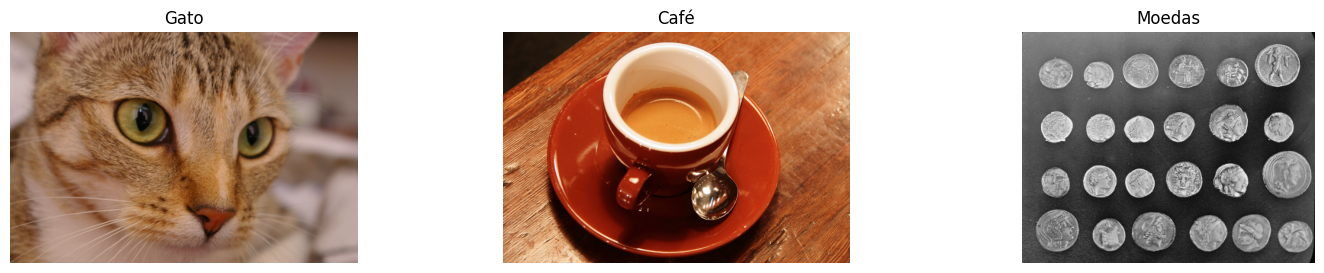

In [44]:
gato = data.cat()
cafe = data.coffee()
moedas = data.coins()

mostrar_imagens([gato, cafe, moedas], titulos=['Gato', 'Café', 'Moedas'], tamanho=3)

In [45]:
def filtro_gaussiano(imagem):
  imagem_filtrada = cv2.GaussianBlur(src=imagem, ksize=(5, 5), sigmaX=5, sigmaY=5)
  return imagem_filtrada

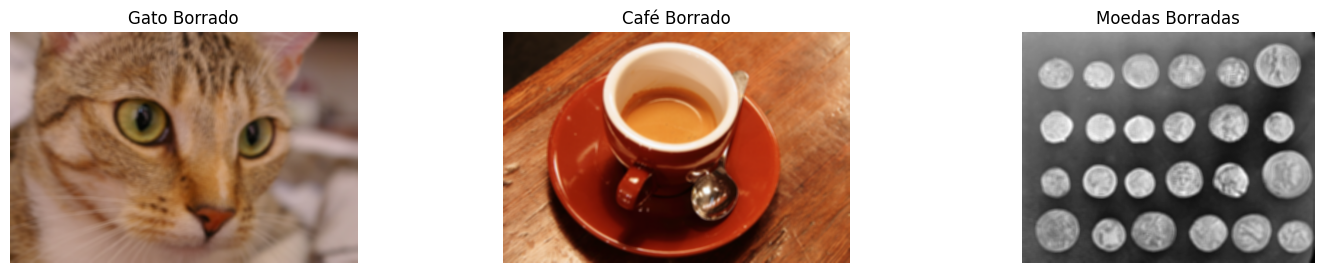

In [46]:
imagens_borradas = imagens=[filtro_gaussiano(img) for img in [gato, cafe, moedas]]
mostrar_imagens(imagens=imagens_borradas,
                titulos=['Gato Borrado', 'Café Borrado', 'Moedas Borradas'],
                tamanho=3)

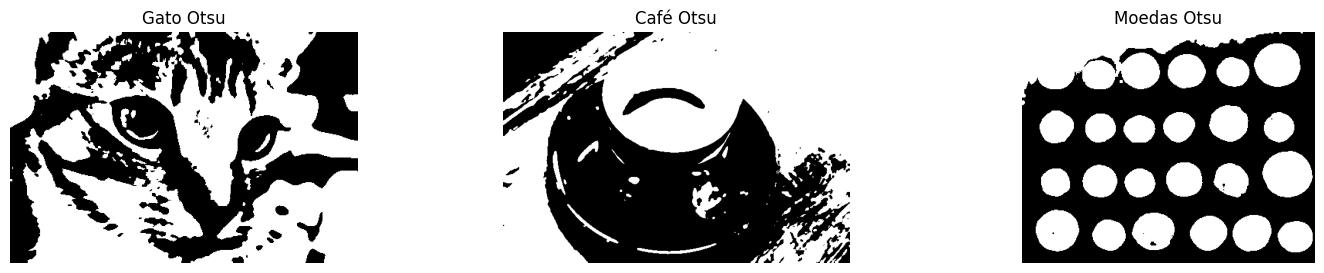

In [47]:
imagens_cinza = []

for img in imagens_borradas:
    # Se a imagem tiver 3 canais (RGB), convertemos para escala de cinza
    if len(img.shape) == 3:
        img_gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    else:
        img_gray = img
    imagens_cinza.append(img_gray)

imagens_limiarizadas = []

for img_gray in imagens_cinza:
    # Aplicando o limiar de Otsu
    _ , img_binaria = cv2.threshold(img_gray,
                                    0,
                                    255,
                                    cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    imagens_limiarizadas.append(img_binaria)

mostrar_imagens(imagens=imagens_limiarizadas,
                titulos=['Gato Otsu', 'Café Otsu', 'Moedas Otsu'],
                tamanho=3)

In [50]:
def limiarizacao_otsu(imagens):
    # Se for uma única imagem (não uma lista/tupla),
    # colocamos em uma lista para processar uniformemente
    is_single = False
    if not isinstance(imagens, (list, tuple)):
        imagens = [imagens]
        is_single = True

    resultados = []

    for img in imagens:
        # Converte para escala de cinza se a imagem for colorida
        if len(img.shape) == 3:
            img_gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        else:
            img_gray = img

        # Aplica a limiarização binária de Otsu
        _, img_binaria = cv2.threshold(img_gray,
                                       0,
                                       255,
                                       cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        resultados.append(img_binaria)

    # Retorna uma única imagem se a entrada foi uma única imagem,
    # caso contrário retorna a lista
    return resultados[0] if is_single else resultados

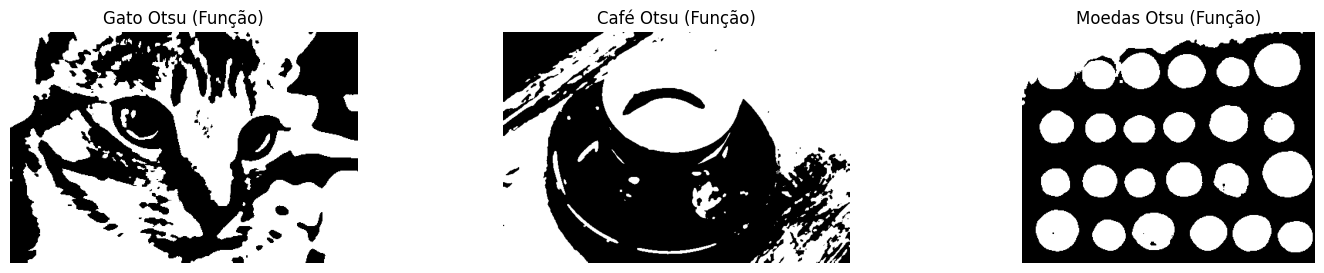

In [51]:
# Demonstração de uso da nova função
imagens_otsu = limiarizacao_otsu(imagens_borradas)

mostrar_imagens(imagens=imagens_otsu,
                titulos=['Gato Otsu (Função)',
                         'Café Otsu (Função)',
                         'Moedas Otsu (Função)'],
                tamanho=3)

In [52]:
def limiarizacao_adaptativa(imagens, block_size=11, c=2):
    # Se for uma única imagem, colocamos em uma lista
    is_single = False
    if not isinstance(imagens, (list, tuple)):
        imagens = [imagens]
        is_single = True

    resultados = []
    for img in imagens:
        # Converte para escala de cinza se a imagem for colorida
        if len(img.shape) == 3:
            img_gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        else:
            img_gray = img

        # Aplica a limiarização adaptativa gaussiana
        img_adaptativa = cv2.adaptiveThreshold(
            img_gray,
            255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY,
            block_size,
            c
        )
        resultados.append(img_adaptativa)

    return resultados[0] if is_single else resultados

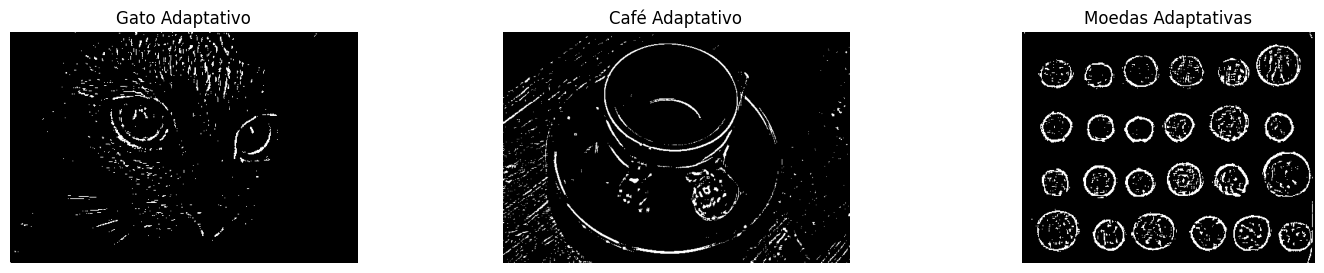

In [68]:
# Demonstração de uso do limiar adaptativo nas imagens borradas
imagens_adaptativas = limiarizacao_adaptativa(imagens_borradas, block_size=5, c=-2)

mostrar_imagens(imagens=imagens_adaptativas,
                titulos=['Gato Adaptativo', 'Café Adaptativo', 'Moedas Adaptativas'],
                tamanho=3)

In [83]:
moedas_adaptativas = limiarizacao_adaptativa(imagens=imagens_borradas[2],
                                             block_size=9,
                                             c=-2)


In [104]:
def calc_qtd_contornos(imagem):
  contornos, _ = cv2.findContours(imagem,
                                  cv2.RETR_EXTERNAL,
                                  cv2.CHAIN_APPROX_SIMPLE)
  contornos = [c for c in contornos if cv2.contourArea(c) >= 100]
  return(contornos)

print('qtd_contornos: ', len(calc_qtd_contornos(moedas_adaptativas)))

qtd_contornos:  24


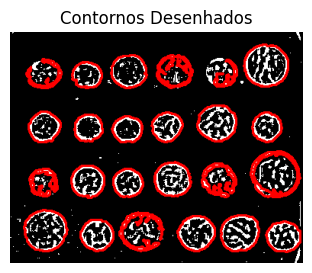

In [105]:
def desenhar_contorno(imagem):
  contornada = cv2.drawContours(image=cv2.cvtColor(imagem, cv2.COLOR_GRAY2RGB),
                   contours=calc_qtd_contornos(imagem),
                   color=(255, 0, 0),
                   thickness=2,
                   contourIdx=-1)
  return contornada

mostrar_imagens([desenhar_contorno(moedas_adaptativas)], ['Contornos Desenhados'], tamanho=3)